In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [2]:
file_path = 'dataset.csv'

try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"[ERROR] File '{file_path}' not found. Please check the file path and try again.")
    exit()

df = df.dropna()

In [3]:
features = [
    'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 
    'instrumentalness', 'liveness', 'valence', 'tempo'
]

X = df[features]
y = df['track_genre']

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [5]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pca_df['Genre'] = y.values

explained_variance = pca.explained_variance_ratio_
print("Explained variance:")
print(f"PC1: {explained_variance[0]:.2%}")
print(f"PC2: {explained_variance[1]:.2%}")
print(f"Sum: {sum(explained_variance):.2%}")

Explained variance:
PC1: 31.93%
PC2: 15.85%
Sum: 47.78%


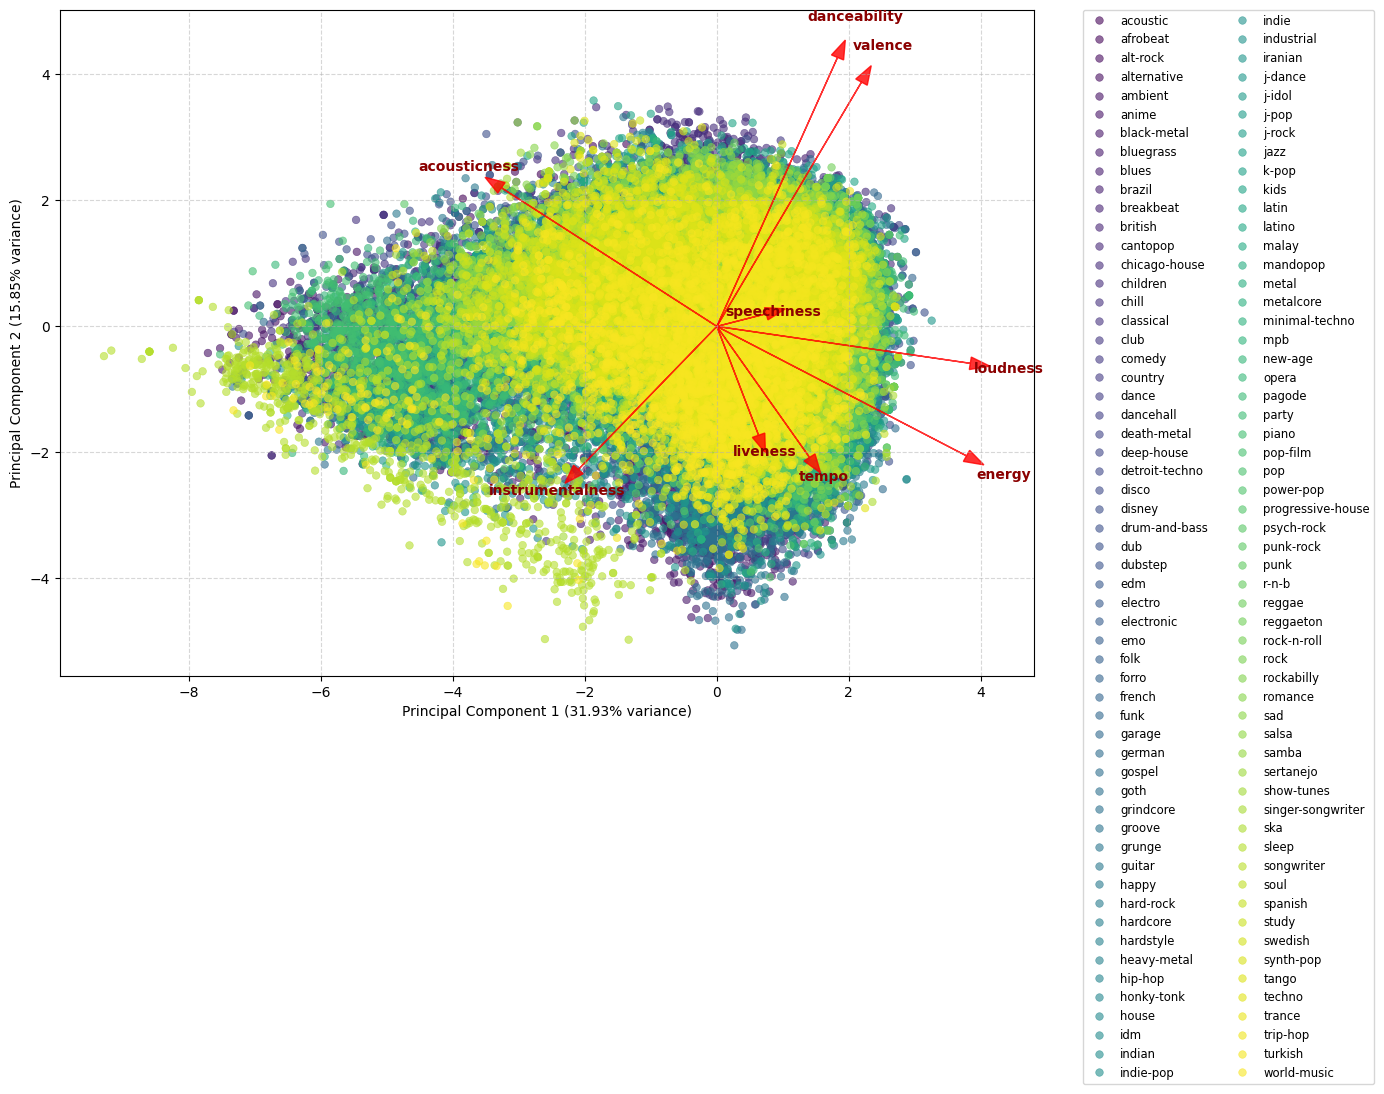

In [6]:
plt.figure(figsize=(14, 10))

sns.scatterplot(
    x='PC1', y='PC2', 
    hue='Genre', 
    data=pca_df, 
    palette='viridis', 
    alpha=0.6, 
    s=30,
    edgecolor=None
)

loadings = pca.components_.T
max_val = np.max(np.abs(principal_components))
scaling_factor = max_val * 0.8

for i, feature in enumerate(features):
    plt.arrow(0, 0, loadings[i, 0] * scaling_factor, loadings[i, 1] * scaling_factor,
              color='red', alpha=0.8, head_width=0.2)
    plt.text(loadings[i, 0] * scaling_factor * 1.15, loadings[i, 1] * scaling_factor * 1.15,
             feature, color='darkred', ha='center', va='center', weight='bold')

plt.xlabel(f'Principal Component 1 ({explained_variance[0]:.2%} variance)')
plt.ylabel(f'Principal Component 2 ({explained_variance[1]:.2%} variance)')
plt.grid(True, linestyle='--', alpha=0.5)

if len(pca_df['Genre'].unique()) > 10:
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0., fontsize='small', ncol=2)
else:
    plt.legend(loc='best')

plt.tight_layout()
plt.show()

In [9]:
loadings_df = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=features)
print(loadings_df.sort_values(by='PC1', ascending=False))
print(loadings_df.sort_values(by='PC2', ascending=False))

                       PC1       PC2
loudness          0.516954 -0.078894
energy            0.509168 -0.276668
valence           0.295026  0.522029
danceability      0.246124  0.574759
tempo             0.189047 -0.279982
speechiness       0.100641  0.026988
liveness          0.085135 -0.232578
instrumentalness -0.282407 -0.305665
acousticness     -0.439341  0.296186
                       PC1       PC2
danceability      0.246124  0.574759
valence           0.295026  0.522029
acousticness     -0.439341  0.296186
speechiness       0.100641  0.026988
loudness          0.516954 -0.078894
liveness          0.085135 -0.232578
energy            0.509168 -0.276668
tempo             0.189047 -0.279982
instrumentalness -0.282407 -0.305665
